In [1]:
# ==============================================================================
# CELL 1: SETUP LIBRARY & AUTO-DISCOVERY 9 FILE DATASET
# ==============================================================================
import gc
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")

SEED = 42
np.random.seed(SEED)
WORK_DIR = Path("/kaggle/working")

# Petakan seluruh 9 file CSV dari /kaggle/input (membedakan folder train/ vs test/)
FILE_MAP = {}
for p in Path("/kaggle/input").rglob("*.csv"):
    folder = p.parent.name.lower()
    key = f"{folder}_{p.stem}" if p.stem in {"shipments", "scan_events", "route_segments", "invoices"} else p.stem
    FILE_MAP[key.lower()] = p

print(f"Total file CSV terdeteksi: {len(FILE_MAP)}")
for k in sorted(FILE_MAP.keys()):
    size_mb = FILE_MAP[k].stat().st_size / (1024 ** 2)
    print(f"  - {k:<22}: {size_mb:7.2f} MB")

Total file CSV terdeteksi: 14
  - couriers              :    1.46 MB
  - customers             :   55.68 MB
  - hubs                  :    0.05 MB
  - promotions            :    0.00 MB
  - sample_submission     :    6.91 MB
  - service_packages      :    0.00 MB
  - test_invoices         :   35.53 MB
  - test_route_segments   :   42.60 MB
  - test_scan_events      :  131.14 MB
  - test_shipments        :   76.17 MB
  - train_invoices        :  121.95 MB
  - train_route_segments  :  146.09 MB
  - train_scan_events     :  449.69 MB
  - train_shipments       :  277.74 MB


# Load Tabel Utama & 5 Tabel Master

In [2]:
def optimize_memory(df: pd.DataFrame, name: str) -> pd.DataFrame:
    mem_before = df.memory_usage(deep=True).sum() / (1024 ** 2)
    for col in df.columns:
        dtype = df[col].dtype
        if pd.api.types.is_integer_dtype(dtype):
            c_min, c_max = df[col].min(), df[col].max()
            if -128 <= c_min and c_max <= 127:
                df[col] = df[col].astype(np.int8)
            elif -32768 <= c_min and c_max <= 32767:
                df[col] = df[col].astype(np.int16)
            else:
                df[col] = df[col].astype(np.int32)
        elif pd.api.types.is_float_dtype(dtype):
            df[col] = df[col].astype(np.float32)
    mem_after = df.memory_usage(deep=True).sum() / (1024 ** 2)
    print(f"✓ {name:<20} | shape={str(df.shape):<16} | RAM: {mem_before:6.1f} MB -> {mem_after:6.1f} MB")
    return df

train_ship = optimize_memory(pd.read_csv(FILE_MAP["train_shipments"]), "train_shipments")
test_ship  = optimize_memory(pd.read_csv(FILE_MAP["test_shipments"]),  "test_shipments")

customers  = optimize_memory(pd.read_csv(FILE_MAP["customers"]),        "customers")
couriers   = optimize_memory(pd.read_csv(FILE_MAP["couriers"]),         "couriers")
hubs       = optimize_memory(pd.read_csv(FILE_MAP["hubs"]),             "hubs")
services   = optimize_memory(pd.read_csv(FILE_MAP["service_packages"]), "service_packages")
promos     = optimize_memory(pd.read_csv(FILE_MAP["promotions"]),       "promotions")

✓ train_shipments      | shape=(1243617, 38)    | RAM: 1143.8 MB ->  978.9 MB
✓ test_shipments       | shape=(362245, 37)     | RAM:  311.8 MB ->  263.8 MB
✓ customers            | shape=(573841, 14)     | RAM:  245.3 MB ->  221.8 MB
✓ couriers             | shape=(23806, 11)      | RAM:    7.6 MB ->    6.8 MB
✓ hubs                 | shape=(654, 9)         | RAM:    0.1 MB ->    0.1 MB
✓ service_packages     | shape=(62, 10)         | RAM:    0.0 MB ->    0.0 MB
✓ promotions           | shape=(34, 6)          | RAM:    0.0 MB ->    0.0 MB


# AUDIT KUALITAS SKEMA, KOLOM KOSONG, & INTEGRITAS FOREIGN KEY

In [3]:
tables_dict = {
    "train_shipments": train_ship,
    "test_shipments": test_ship,
    "customers": customers,
    "couriers": couriers,
    "hubs": hubs,
    "service_packages": services,
    "promotions": promos,
}

# 1. Ringkasan missing value dan jumlah nilai unik tiap kolom
audit_rows = []
for tname, df_t in tables_dict.items():
    for col in df_t.columns:
        audit_rows.append({
            "table": tname,
            "column": col,
            "dtype": str(df_t[col].dtype),
            "missing_%": round(df_t[col].isna().mean() * 100, 2),
            "n_unique": df_t[col].nunique(dropna=True),
        })
audit_df = pd.DataFrame(audit_rows)

print("=== 1. KOLOM BERMASALAH (100% KOSONG ATAU KONSTAN n_unique <= 1) ===")
display(audit_df[(audit_df["missing_%"] == 100.0) | (audit_df["n_unique"] <= 1)])

print("\n=== 2. KOLOM DENGAN MISSING VALUE PARSIAL (0% < missing < 100%) ===")
display(audit_df[(audit_df["missing_%"] > 0) & (audit_df["missing_%"] < 100)])

print("\n=== 3. CEK DUPLIKASI PRIMARY KEY & CAKUPAN FOREIGN KEY ===")
pk_map = {
    "train_shipments": "shipment_id",
    "test_shipments": "shipment_id",
    "customers": "customer_id",
    "couriers": "courier_id",
    "hubs": "hub_id",
    "service_packages": services.columns[0],
    "promotions": promos.columns[0],
}
for tname, pk in pk_map.items():
    dupes = tables_dict[tname].duplicated(subset=[pk]).sum()
    print(f"  PK [{tname:<18} | {pk:<20}] -> duplikat = {dupes}")

print("\nKecocokan Foreign Key di tabel shipments:")
for col_fk, ref_df in [
    ("customer_id", customers),
    ("courier_id", couriers),
    ("hub_id", hubs),
    ("origin_hub_id", hubs),
    ("dest_hub_id", hubs),
    (services.columns[0], services),
    (promos.columns[0], promos),
]:
    if col_fk in train_ship.columns:
        valid_ids = set(ref_df[col_fk].dropna())
        tr_ok = train_ship[col_fk].dropna().isin(valid_ids).mean() * 100
        te_ok = test_ship[col_fk].dropna().isin(valid_ids).mean() * 100
        print(f"  FK [{col_fk:<20}] -> Match Train: {tr_ok:6.2f}% | Match Test: {te_ok:6.2f}%")

=== 1. KOLOM BERMASALAH (100% KOSONG ATAU KONSTAN n_unique <= 1) ===


,table,column,dtype,missing_%,n_unique



=== 2. KOLOM DENGAN MISSING VALUE PARSIAL (0% < missing < 100%) ===


,table,column,dtype,missing_%,n_unique
7,train_shipments,volume_l,float32,2.98,1393
45,test_shipments,volume_l,float32,3.04,1099
79,customers,credit_score,float32,1.99,525898
94,couriers,courier_score,float32,1.08,5



=== 3. CEK DUPLIKASI PRIMARY KEY & CAKUPAN FOREIGN KEY ===
  PK [train_shipments    | shipment_id         ] -> duplikat = 0
  PK [test_shipments     | shipment_id         ] -> duplikat = 0
  PK [customers          | customer_id         ] -> duplikat = 0
  PK [couriers           | courier_id          ] -> duplikat = 0
  PK [hubs               | hub_id              ] -> duplikat = 0
  PK [service_packages   | package_id          ] -> duplikat = 0
  PK [promotions         | promo_id            ] -> duplikat = 0

Kecocokan Foreign Key di tabel shipments:
  FK [customer_id         ] -> Match Train: 100.00% | Match Test: 100.00%
  FK [courier_id          ] -> Match Train: 100.00% | Match Test: 100.00%
  FK [hub_id              ] -> Match Train: 100.00% | Match Test: 100.00%
  FK [package_id          ] -> Match Train: 100.00% | Match Test: 100.00%
  FK [promo_id            ] -> Match Train:  16.98% | Match Test:  17.04%


=== DISTRIBUSI 7 KELAS TARGET (TRAIN) ===


,jumlah_pengiriman,proporsi_%,rasio_terhadap_normal
status_penanganan,,,
normal,473531,38.077,1.0000
konfirmasi_alamat,272911,21.945,0.5763
tertunda_operasional,185496,14.916,0.3917
gagal_antar_awal,124341,9.998,0.2626
retur_pengirim,87740,7.055,0.1853
rusak_perjalanan,61942,4.981,0.1308
klaim_hilang,37656,3.028,0.0795



Baseline Floor (Selalu Prediksi 'normal') Macro F1 : 0.07879
Rasio Ketimpangan (normal vs klaim_hilang)         : 12.6 : 1


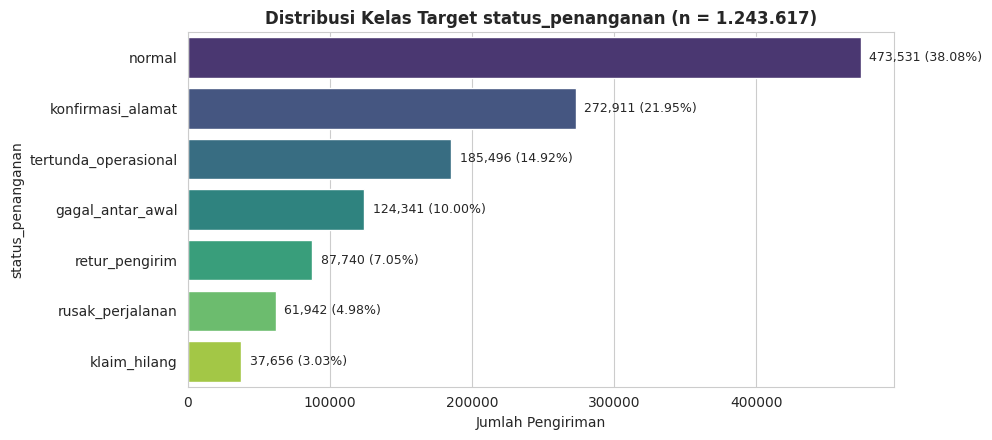

In [4]:
from sklearn.metrics import f1_score

cnt = train_ship["status_penanganan"].value_counts()
pct = (train_ship["status_penanganan"].value_counts(normalize=True) * 100).round(3)

target_df = pd.DataFrame({
    "jumlah_pengiriman": cnt,
    "proporsi_%": pct,
    "rasio_terhadap_normal": (cnt / cnt["normal"]).round(4),
})
print("=== DISTRIBUSI 7 KELAS TARGET (TRAIN) ===")
display(target_df)

# Lantai skor jika model hanya menebak kelas mayoritas ('normal')
y_true_str = train_ship["status_penanganan"].values
floor_f1 = f1_score(y_true_str, np.full_like(y_true_str, "normal"), average="macro")
print(f"\nBaseline Floor (Selalu Prediksi 'normal') Macro F1 : {floor_f1:.5f}")
print(f"Rasio Ketimpangan (normal vs klaim_hilang)         : {cnt['normal'] / cnt['klaim_hilang']:.1f} : 1")

# Plot bar horizontal ringkas untuk dokumentasi Write-Up
plt.figure(figsize=(10, 4.5))
ax = sns.barplot(x=cnt.values, y=cnt.index, palette="viridis")
plt.title("Distribusi Kelas Target status_penanganan (n = 1.243.617)", fontweight="bold")
plt.xlabel("Jumlah Pengiriman")
for i, v in enumerate(cnt.values):
    ax.text(v + 6000, i, f"{v:,} ({pct.iloc[i]:.2f}%)", va="center", fontsize=9)
plt.tight_layout()
plt.show()

# FORENSIK SPLIT TRAIN VS TEST (ENTITY OVERLAP, WAKTU, & DRIFT)

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

print("=== 1. OVERLAP ENTITAS ANTARA TRAIN DAN TEST ===")
for col in ["customer_id", "courier_id", "hub_id", "package_id", "promo_id"]:
    tr_set = set(train_ship[col].dropna())
    te_set = set(test_ship[col].dropna())
    ent_overlap = len(tr_set & te_set) / max(len(te_set), 1) * 100
    row_overlap = test_ship[col].isin(tr_set).mean() * 100
    print(f"  {col:<14} | Unik Train: {len(tr_set):>7,} | Unik Test: {len(te_set):>7,} | Overlap Entitas: {ent_overlap:6.2f}% ({row_overlap:6.2f}% baris test)")

print("\n=== 2. PERBANDINGAN DISTRIBUSI WAKTU (BULAN / HARI / JAM) ===")
time_cols = [c for c in train_ship.columns if any(k in c.lower() for k in ["month", "bulan", "dow", "day", "hour", "jam", "date", "tgl"])]
for tc in time_cols:
    if train_ship[tc].nunique() <= 31:
        comp = pd.DataFrame({
            "train_%": (train_ship[tc].value_counts(normalize=True) * 100).round(2),
            "test_%":  (test_ship[tc].value_counts(normalize=True) * 100).round(2),
        }).fillna(0)
        print(f"\nDistribusi [{tc}]:")
        display(comp.T)

print("\n=== 3. ADVERSARIAL VALIDATION (TRAIN=0 VS TEST=1) ===")
num_cols = [c for c in train_ship.columns if c in test_ship.columns and c != "shipment_id" and pd.api.types.is_numeric_dtype(train_ship[c])]
rng = np.random.default_rng(SEED)
n_s = 100_000
X_adv = pd.concat([
    train_ship.iloc[rng.choice(len(train_ship), n_s, replace=False)][num_cols].fillna(-999),
    test_ship.iloc[rng.choice(len(test_ship),   n_s, replace=False)][num_cols].fillna(-999),
], ignore_index=True)
y_adv = np.array([0] * n_s + [1] * n_s)

oof_adv = np.zeros(len(y_adv))
imp_adv = np.zeros(len(num_cols))
for tr_i, va_i in StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED).split(X_adv, y_adv):
    rf = RandomForestClassifier(n_estimators=60, max_depth=7, n_jobs=-1, random_state=SEED)
    rf.fit(X_adv.iloc[tr_i], y_adv[tr_i])
    oof_adv[va_i] = rf.predict_proba(X_adv.iloc[va_i])[:, 1]
    imp_adv += rf.feature_importances_ / 3.0

print(f">>> Adversarial ROC-AUC = {roc_auc_score(y_adv, oof_adv):.5f} (0.50 = acak | >0.60 = ada shift) <<<")
display(pd.DataFrame({"feature": num_cols, "drift_imp": imp_adv}).sort_values("drift_imp", ascending=False).head(8))

=== 1. OVERLAP ENTITAS ANTARA TRAIN DAN TEST ===
  customer_id    | Unik Train: 508,086 | Unik Test: 268,812 | Overlap Entitas:  88.51% ( 88.58% baris test)
  courier_id     | Unik Train:  23,806 | Unik Test:  23,806 | Overlap Entitas: 100.00% (100.00% baris test)
  hub_id         | Unik Train:     654 | Unik Test:     654 | Overlap Entitas: 100.00% (100.00% baris test)
  package_id     | Unik Train:      62 | Unik Test:      62 | Overlap Entitas: 100.00% (100.00% baris test)
  promo_id       | Unik Train:      35 | Unik Test:      35 | Overlap Entitas: 100.00% (100.00% baris test)

=== 2. PERBANDINGAN DISTRIBUSI WAKTU (BULAN / HARI / JAM) ===

Distribusi [ship_month]:


ship_month,1,2,3,4,5,6,7,8,9,10,11,12
train_%,7.99,6.96,8.98,8.05,7.99,6.98,7.03,7.96,8.04,10.03,11.03,8.97
test_%,7.81,6.85,8.86,7.91,7.52,6.54,6.19,7.54,7.80,10.88,12.37,9.74



Distribusi [ship_dow]:


ship_dow,0,1,2,3,4,5,6
train_%,14.28,14.25,14.29,14.25,14.32,14.25,14.35
test_%,14.30,14.32,14.34,14.17,14.32,14.27,14.28



Distribusi [ship_hour]:


ship_hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
train_%,0.20,0.23,0.43,0.75,1.25,1.92,2.86,4.02,5.36,6.73,7.97,8.9,9.38,9.43,8.86,7.93,6.70,5.36,4.04,2.89,1.93,1.24,0.74,0.87
test_%,0.22,0.23,0.40,0.73,1.27,1.96,2.87,4.02,5.39,6.78,7.92,8.9,9.41,9.38,8.93,7.91,6.68,5.31,4.02,2.86,1.94,1.24,0.73,0.88



=== 3. ADVERSARIAL VALIDATION (TRAIN=0 VS TEST=1) ===
>>> Adversarial ROC-AUC = 0.51203 (0.50 = acak | >0.60 = ada shift) <<<


,feature,drift_imp
4,ship_month,0.133092
22,varian_cuaca_rute,0.074493
19,skor_prioritas_kirim,0.071964
3,distance_km,0.068485
23,indeks_waktu_proses,0.065803
21,faktor_muatan_internal,0.065611
20,indeks_rute_sekunder,0.065421
24,skor_kualitas_cek,0.065321


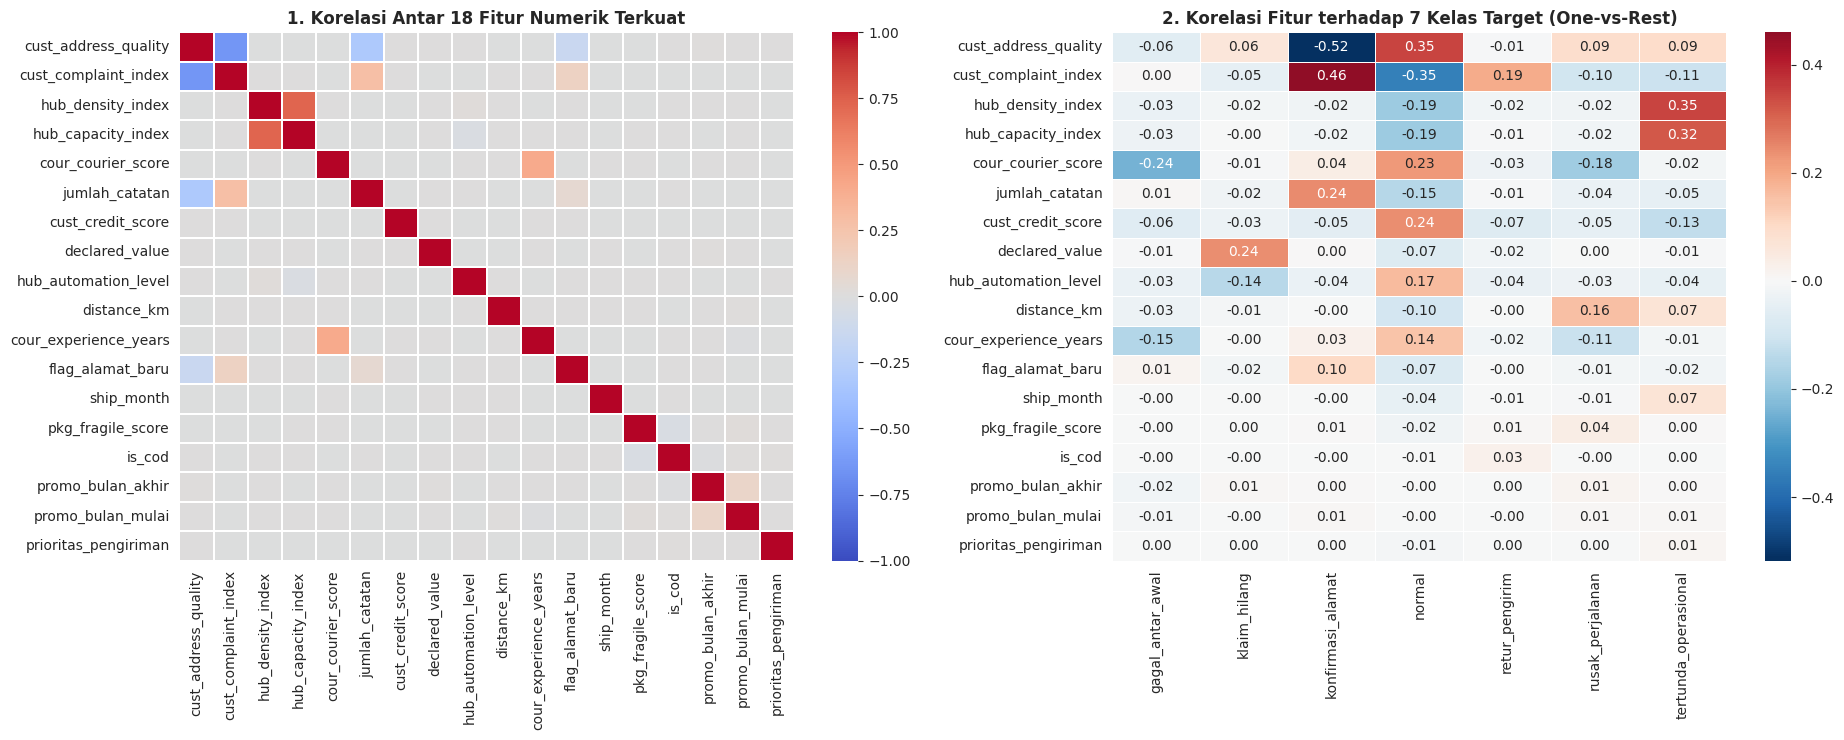

0

In [6]:
df_corr = train_ship.sample(n=120_000, random_state=SEED).copy()
for ref_df, fk, pref in [
    (customers, "customer_id", "cust_"),
    (couriers,  "courier_id",  "cour_"),
    (hubs,      "hub_id",      "hub_"),
    (services,  "package_id",  "pkg_"),
    (promos,    "promo_id",    "promo_"),
]:
    ren = {c: f"{pref}{c}" for c in ref_df.columns if c != fk}
    df_corr = df_corr.merge(ref_df.rename(columns=ren), on=fk, how="left")

num_feats = [
    c for c in df_corr.select_dtypes(include=[np.number]).columns
    if not c.endswith("_id") and df_corr[c].nunique(dropna=True) > 1
]

# Hitung korelasi One-vs-Rest (fitur numerik vs biner tiap kelas y == k)
CLASSES = sorted(df_corr["status_penanganan"].unique())
y_dummies = pd.DataFrame({cls: (df_corr["status_penanganan"] == cls).astype("float32") for cls in CLASSES})
corr_target = df_corr[num_feats].apply(lambda s: y_dummies.corrwith(s)).T
top_feats = corr_target.abs().max(axis=1).sort_values(ascending=False).head(18).index

fig, axes = plt.subplots(1, 2, figsize=(19, 7.5))

# Panel 1: Korelasi Antar 18 Fitur Numerik Terkuat
sns.heatmap(df_corr[top_feats].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.3, ax=axes[0])
axes[0].set_title("1. Korelasi Antar 18 Fitur Numerik Terkuat", fontweight="bold")

# Panel 2: Korelasi Fitur vs 7 Kelas Target (One-vs-Rest)
sns.heatmap(corr_target.loc[top_feats], cmap="RdBu_r", center=0, annot=True, fmt=".2f", linewidths=0.4, ax=axes[1])
axes[1].set_title("2. Korelasi Fitur terhadap 7 Kelas Target (One-vs-Rest)", fontweight="bold")

plt.tight_layout()
plt.savefig(WORK_DIR / "eda_correlation_2panel.png", dpi=150)
plt.show()

del df_corr
gc.collect()

# Korelasi Sluruh FItur

Total fitur numerik statis yang dianalisis: 54 fitur

=== TABEL KORELASI LENGKAP SEMUA FITUR VS 7 KELAS TARGET ===


,gagal_antar_awal,klaim_hilang,konfirmasi_alamat,normal,retur_pengirim,rusak_perjalanan,tertunda_operasional,max_abs_corr
cust_address_quality,-0.0564,0.0610,-0.5179,0.3481,-0.0077,0.0920,0.0943,0.5179
cust_complaint_index,0.0036,-0.0480,0.4605,-0.3520,0.1914,-0.0973,-0.1126,0.4605
hub_density_index,-0.0329,-0.0160,-0.0251,-0.1892,-0.0173,-0.0246,0.3486,0.3486
hub_capacity_index,-0.0269,-0.0040,-0.0212,-0.1867,-0.0082,-0.0198,0.3204,0.3204
cour_courier_score,-0.2451,-0.0075,0.0394,0.2266,-0.0256,-0.1809,-0.0153,0.2451
jumlah_catatan,0.0084,-0.0249,0.2443,-0.1502,-0.0072,-0.0375,-0.0458,0.2443
cust_credit_score,-0.0598,-0.0311,-0.0540,0.2417,-0.0671,-0.0476,-0.1236,0.2417
declared_value,-0.0053,0.2405,0.0001,-0.0696,-0.0181,0.0024,-0.0054,0.2405
hub_automation_level,-0.0338,-0.1415,-0.0351,0.1647,-0.0359,-0.0271,-0.0443,0.1647
distance_km,-0.0349,-0.0086,0.0009,-0.0967,-0.0036,0.1574,0.0704,0.1574


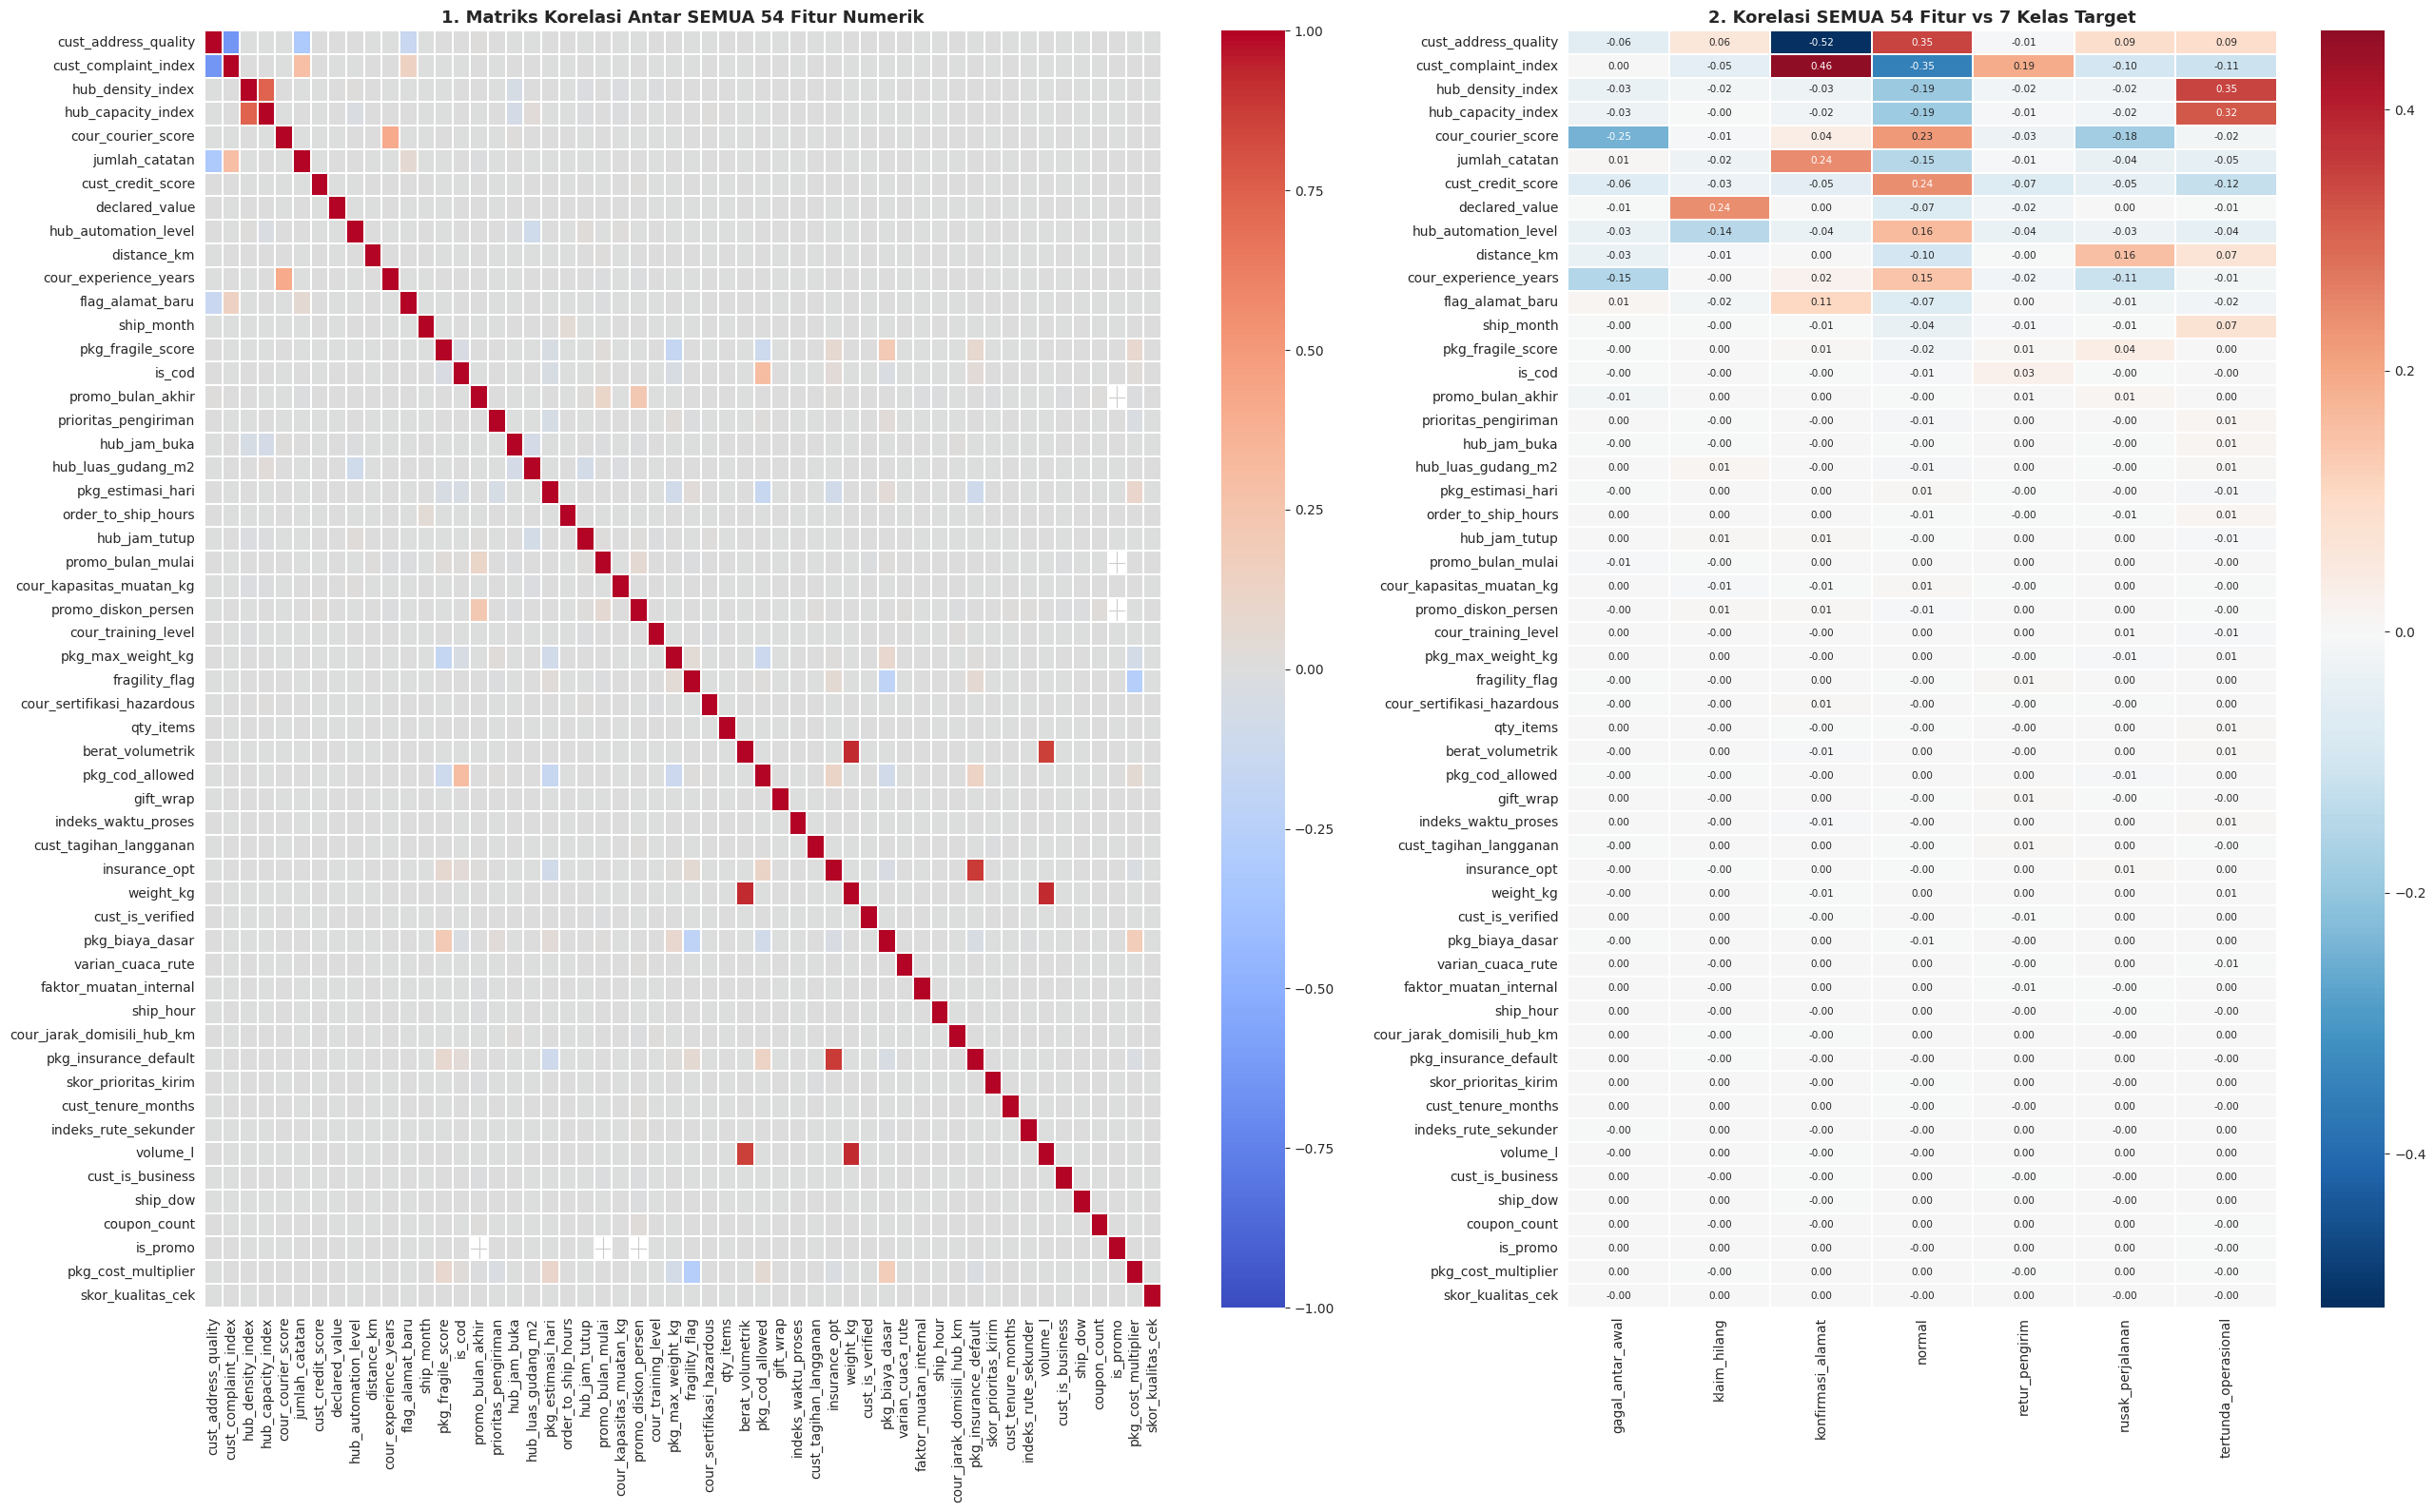

20447

In [7]:
df_full_corr = train_ship.sample(n=150_000, random_state=SEED).copy()
for ref_df, fk, pref in [
    (customers, "customer_id", "cust_"),
    (couriers,  "courier_id",  "cour_"),
    (hubs,      "hub_id",      "hub_"),
    (services,  "package_id",  "pkg_"),
    (promos,    "promo_id",    "promo_"),
]:
    ren = {c: f"{pref}{c}" for c in ref_df.columns if c != fk}
    df_full_corr = df_full_corr.merge(ref_df.rename(columns=ren), on=fk, how="left")

# Ambil SEMUA kolom numerik (kecuali ID)
all_num_cols = [c for c in df_full_corr.select_dtypes(include=[np.number]).columns if not c.endswith("_id")]
print(f"Total fitur numerik statis yang dianalisis: {len(all_num_cols)} fitur")

# 1. Hitung korelasi SEMUA fitur terhadap masing-masing dari 7 kelas target
CLASSES = sorted(df_full_corr["status_penanganan"].unique())
y_dum = pd.DataFrame({cls: (df_full_corr["status_penanganan"] == cls).astype("float32") for cls in CLASSES})
corr_all_target = df_full_corr[all_num_cols].apply(lambda s: y_dum.corrwith(s)).T
corr_all_target["max_abs_corr"] = corr_all_target.abs().max(axis=1)
corr_all_target = corr_all_target.sort_values("max_abs_corr", ascending=False)

print("\n=== TABEL KORELASI LENGKAP SEMUA FITUR VS 7 KELAS TARGET ===")
display(corr_all_target.round(4))
corr_all_target.to_csv(WORK_DIR / "eda_all_features_target_corr.csv")

# 2. Gambar 2 Grafik Besar untuk SEMUA fitur numerik
ordered_cols = corr_all_target.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(26, 16), gridspec_kw={"width_ratios": [1.35, 1.0]})

sns.heatmap(
    df_full_corr[ordered_cols].corr(),
    cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.2, ax=axes[0]
)
axes[0].set_title(f"1. Matriks Korelasi Antar SEMUA {len(ordered_cols)} Fitur Numerik", fontsize=13, fontweight="bold")

sns.heatmap(
    corr_all_target[CLASSES],
    cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7.5}, linewidths=0.3, ax=axes[1]
)
axes[1].set_title(f"2. Korelasi SEMUA {len(ordered_cols)} Fitur vs 7 Kelas Target", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig(WORK_DIR / "eda_all_features_correlation.png", dpi=150)
plt.show()

del df_full_corr
gc.collect()

AUDIT 3 TABEL TRANSAKSIONAL (SCAN_EVENTS, ROUTE_SEGMENTS, INVOICES)

In [10]:
for tbl in ["scan_events", "route_segments", "invoices"]:
    print(f"\n==================== {tbl.upper()} ====================")
    tr_t = pd.read_csv(FILE_MAP[f"train_{tbl}"])
    te_t = pd.read_csv(FILE_MAP[f"test_{tbl}"])
    print(f"Shape Train: {tr_t.shape} | Shape Test: {te_t.shape}")
    print(f"Kolom      : {list(tr_t.columns)}")

    cnt_tr = tr_t.groupby("shipment_id").size().reindex(train_ship["shipment_id"], fill_value=0)
    cnt_te = te_t.groupby("shipment_id").size().reindex(test_ship["shipment_id"],  fill_value=0)
    print(f"Rata-rata baris/paket -> Train: {cnt_tr.mean():.2f} (tanpa catatan: {(cnt_tr==0).mean()*100:.2f}%) | Test: {cnt_te.mean():.2f} (tanpa catatan: {(cnt_te==0).mean()*100:.2f}%)")

    # 1. SCAN_EVENTS: Pertahankan urutan asli baris CSV (JANGAN sort berdasarkan event_id!)
    if tbl == "scan_events":
        last_ev = tr_t.groupby("shipment_id", sort=False)["event_type"].last().reindex(train_ship["shipment_id"])
        ct = (pd.crosstab(last_ev, train_ship["status_penanganan"], normalize="index") * 100).round(2)
        ct["jumlah_paket"] = last_ev.value_counts()
        print("\n>>> Crosstab TRUE Last Scan (Urutan Asli CSV) vs Target (%) <<<")
        display(ct)

    # 2. INVOICES: Cek dampak is_penalty dan keberadaan invoice_type == 'klaim'
    if tbl == "invoices":
        has_pen = (tr_t.groupby("shipment_id")["is_penalty"].max().reindex(train_ship["shipment_id"], fill_value=0) > 0).astype(int)
        print("\n>>> Crosstab Invoice Penalty (is_penalty > 0) vs Target (%) <<<")
        display((pd.crosstab(has_pen, train_ship["status_penanganan"], normalize="index") * 100).round(2))

        tr_t["is_klaim"] = (tr_t["invoice_type"].astype(str).str.lower() == "klaim").astype(int)
        has_klm = tr_t.groupby("shipment_id")["is_klaim"].max().reindex(train_ship["shipment_id"], fill_value=0)
        print("\n>>> Crosstab Invoice Klaim (invoice_type == 'klaim') vs Target (%) <<<")
        display((pd.crosstab(has_klm, train_ship["status_penanganan"], normalize="index") * 100).round(2))

    del tr_t, te_t
    gc.collect()


==================== SCAN_EVENTS ====================
Shape Train: (6837111, 8) | Shape Test: (1993132, 8)
Kolom      : ['event_id', 'shipment_id', 'hub_id', 'event_type', 'gap_hours', 'device_type', 'scan_quality', 'is_manual']
Rata-rata baris/paket -> Train: 5.50 (tanpa catatan: 0.00%) | Test: 5.50 (tanpa catatan: 0.00%)

>>> Crosstab TRUE Last Scan (Urutan Asli CSV) vs Target (%) <<<


status_penanganan,jumlah_paket
event_type,
selesai,831294
upaya_antar,412323



==================== ROUTE_SEGMENTS ====================
Shape Train: (2200148, 8) | Shape Test: (641446, 8)
Kolom      : ['segment_id', 'shipment_id', 'urutan', 'moda', 'jarak_segmen_km', 'durasi_jam', 'segmen_hub_id', 'biaya_segmen']
Rata-rata baris/paket -> Train: 1.77 (tanpa catatan: 0.00%) | Test: 1.77 (tanpa catatan: 0.00%)

==================== INVOICES ====================
Shape Train: (1467722, 12) | Shape Test: (427458, 12)
Kolom      : ['invoice_id', 'shipment_id', 'customer_id', 'invoice_type', 'amount', 'discount', 'tax', 'payment_method', 'payment_status', 'issued_month', 'days_to_pay', 'is_penalty']
Rata-rata baris/paket -> Train: 1.18 (tanpa catatan: 0.00%) | Test: 1.18 (tanpa catatan: 0.00%)

>>> Crosstab Invoice Penalty (is_penalty > 0) vs Target (%) <<<


status_penanganan
is_penalty



>>> Crosstab Invoice Klaim (invoice_type == 'klaim') vs Target (%) <<<


status_penanganan
is_klaim


In [12]:
from sklearn.preprocessing import LabelEncoder

NOISE_COLS = [
    "indeks_waktu_proses", "varian_cuaca_rute", "faktor_muatan_internal",
    "skor_prioritas_kirim", "indeks_rute_sekunder", "skor_kualitas_cek",
]

def build_clean_base(df_ship: pd.DataFrame) -> pd.DataFrame:
    df = df_ship.drop(columns=[c for c in NOISE_COLS if c in df_ship.columns]).copy()
    for ref_df, fk, pref in [
        (customers, "customer_id", "cust_"),
        (couriers,  "courier_id",  "cour_"),
        (hubs,      "hub_id",      "hub_"),
        (services,  "package_id",  "pkg_"),
        (promos,    "promo_id",    "promo_"),
    ]:
        ren = {c: f"{pref}{c}" for c in ref_df.columns if c != fk}
        df = df.merge(ref_df.rename(columns=ren), on=fk, how="left")
    return df

master_train = optimize_memory(build_clean_base(train_ship), "master_train_base")
master_test  = optimize_memory(build_clean_base(test_ship),  "master_test_base")

le = LabelEncoder()
y_all = le.fit_transform(master_train["status_penanganan"]).astype(np.int32)
CLASSES = list(le.classes_)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = np.array(list(skf.split(master_train, y_all)), dtype=object)

assert len(master_train) == 1_243_617 and len(master_test) == 362_245
assert set(master_train.columns) - {"status_penanganan"} == set(master_test.columns)

master_train.to_parquet(WORK_DIR / "master_train_base.parquet", index=False, compression="snappy")
master_test.to_parquet(WORK_DIR  / "master_test_base.parquet",  index=False, compression="snappy")
np.save(WORK_DIR / "y_all.npy", y_all)
np.save(WORK_DIR / "folds.npy", folds)
np.save(WORK_DIR / "classes.npy", np.array(CLASSES))

print("\n✓ SELURUH FONDASI NOTEBOOK 01 TERSIMPAN:")
print(f"  - master_train_base.parquet : {master_train.shape}")
print(f"  - master_test_base.parquet  : {master_test.shape}")
print(f"  - classes.npy               : {CLASSES}")


✓ master_train_base    | shape=(1243617, 77)    | RAM: 2056.2 MB -> 2046.7 MB
✓ master_test_base     | shape=(362245, 76)     | RAM:  577.6 MB ->  574.9 MB

✓ SELURUH FONDASI NOTEBOOK 01 TERSIMPAN:
  - master_train_base.parquet : (1243617, 77)
  - master_test_base.parquet  : (362245, 76)
  - classes.npy               : ['gagal_antar_awal', 'klaim_hilang', 'konfirmasi_alamat', 'normal', 'retur_pengirim', 'rusak_perjalanan', 'tertunda_operasional']
